# Credit Card Default Prediction Using Logistic Regression

### This project uses Logistic Regression to predict whether a credit card customer will default on their next month's payment based on demographic and financial information.

### The model is trained and evaluated using real-world credit card data, with performance measured through Jaccard Score, Confusion Matrix, Precision, Recall, and F1-Score.

## Import Libraries
#### Import essential libraries for data manipulation, numerical operations, visualization, preprocessing, and optimization.

In [3]:
import numpy as np
import pandas as pd
import pylab as pl
import matplotlib.pyplot as plt
from sklearn import preprocessing
%matplotlib inline
import scipy.optimize as opt

## Load Dataset
#### Install the required Excel reader, load the credit card dataset into Pandas DataFrames, and preview the first five rows.

In [10]:
!pip install xlrd
data = pd.read_excel(r"C:\mac\default of credit card clients.xls")
df = pd.read_excel(r"C:\mac\default of credit card clients.xls")

data.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


## Rename Dataset Columns
#### Assign meaningful names to dataset columns for better readability and easier data analysis.

In [13]:
df.columns = [
    'ID',
    'LIMIT_BAL',
    'SEX',
    'EDUCATION',
    'MARRIAGE',
    'AGE',
    'PAY_0',
    'PAY_2',
    'PAY_3',
    'PAY_4',
    'PAY_5',
    'PAY_6',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'PAY_AMT1',
    'PAY_AMT2',
    'PAY_AMT3',
    'PAY_AMT4',
    'PAY_AMT5',
    'PAY_AMT6',
    'default'
]

## Data Cleaning and Preprocessing
#### Remove extra header rows, select relevant features, convert the target variable to integer, and prepare the dataset for machine learning.

In [19]:
# Remove extra header row
df = df[
    df['default'].astype(str).str.strip().str.lower()
    != 'default payment next month'
].copy()

# Select required columns
credit_df = df[[
    'ID',
    'LIMIT_BAL',
    'SEX',
    'EDUCATION',
    'MARRIAGE',
    'AGE',
    'PAY_0',
    'PAY_2',
    'PAY_3',
    'PAY_4',
    'PAY_5',
    'PAY_6',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'PAY_AMT1',
    'PAY_AMT2',
    'PAY_AMT3',
    'PAY_AMT4',
    'PAY_AMT5',
    'PAY_AMT6',
    'default'
]].copy()

# Convert target to integer
credit_df['default'] = credit_df['default'].astype(int)

credit_df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Feature Selection (X)
#### Select 23 relevant input features and convert them into a NumPy array for machine learning.

In [20]:
X = np.asarray(credit_df[[
    'LIMIT_BAL',
    'SEX',
    'EDUCATION',
    'MARRIAGE',
    'AGE',
    'PAY_0',
    'PAY_2',
    'PAY_3',
    'PAY_4',
    'PAY_5',
    'PAY_6',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'PAY_AMT1',
    'PAY_AMT2',
    'PAY_AMT3',
    'PAY_AMT4',
    'PAY_AMT5',
    'PAY_AMT6'
]])

X[0:5]

array([[20000, 2, 2, 1, 24, 2, 2, -1, -1, -2, -2, 3913, 3102, 689, 0, 0,
        0, 0, 689, 0, 0, 0, 0],
       [120000, 2, 2, 2, 26, -1, 2, 0, 0, 0, 2, 2682, 1725, 2682, 3272,
        3455, 3261, 0, 1000, 1000, 1000, 0, 2000],
       [90000, 2, 2, 2, 34, 0, 0, 0, 0, 0, 0, 29239, 14027, 13559, 14331,
        14948, 15549, 1518, 1500, 1000, 1000, 1000, 5000],
       [50000, 2, 2, 1, 37, 0, 0, 0, 0, 0, 0, 46990, 48233, 49291, 28314,
        28959, 29547, 2000, 2019, 1200, 1100, 1069, 1000],
       [50000, 1, 2, 1, 57, -1, 0, -1, 0, 0, 0, 8617, 5670, 35835, 20940,
        19146, 19131, 2000, 36681, 10000, 9000, 689, 679]], dtype=object)

## Target Variable (y)
#### Extract the target column (`default`) and convert it into a NumPy array for binary classification.

In [43]:
y = np.asarray(credit_df['default'])
y[0:5]

array([1, 1, 0, 0, 0])

## Feature Scaling (StandardScaler)
#### Standardize input features to a common scale using mean and standard deviation to improve Logistic Regression performance.

In [44]:
X = preprocessing.StandardScaler().fit(X).transform(X)
X[0:5]

array([[-1.13672015,  0.81016074,  0.18582826, -1.05729503, -1.24601985,
         1.79456386,  1.78234817, -0.69666346, -0.66659873, -1.53004603,
        -1.48604076, -0.64250107, -0.64739923, -0.66799331, -0.67249727,
        -0.66305853, -0.65272422, -0.34194162, -0.22708564, -0.29680127,
        -0.30806256, -0.31413612, -0.29338206],
       [-0.3659805 ,  0.81016074,  0.18582826,  0.85855728, -1.02904717,
        -0.87499115,  1.78234817,  0.1388648 ,  0.18874609,  0.23491652,
         1.99231551, -0.65921875, -0.66674657, -0.63925429, -0.62163594,
        -0.60622927, -0.59796638, -0.34194162, -0.21358766, -0.24000461,
        -0.24422965, -0.31413612, -0.18087821],
       [-0.59720239,  0.81016074,  0.18582826,  0.85855728, -0.16115646,
         0.01486052,  0.1117361 ,  0.1388648 ,  0.18874609,  0.23491652,
         0.25313738, -0.29855966, -0.49389911, -0.48240819, -0.44973025,
        -0.41718767, -0.39162956, -0.25029158, -0.19188673, -0.24000461,
        -0.24422965, -0.2486

## Train-Test Split
#### Split the dataset into 80% training and 20% testing sets to train and evaluate the Logistic Regression model.

In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2 , random_state=4)
print('trainset', X_train.shape,y_train.shape)
print('testset', X_test.shape,y_test.shape)

trainset (24000, 23) (24000,)
testset (6000, 23) (6000,)


## Logistic Regression Training
#### Initialize and train a Logistic Regression classifier using L2 regularization and the Liblinear optimization solver.

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
LR = LogisticRegression(C=0.01, solver='liblinear').fit(X_train,y_train)

## Model Prediction
#### Generate predictions on the test set using the trained Logistic Regression model and compare predicted labels with actual values.

In [50]:
yhat = LR.predict(X_test)
print(yhat)
print(y)

[0 0 0 ... 0 0 1]
[1 1 0 ... 1 1 1]


## Prediction Probabilities
#### Calculate the probability of each credit card customer belonging to the default and non-default classes using Logistic Regression.

yhat_prob = LR.predict_proba(X_test)
yhat_prob

## Jaccard Score
#### Evaluate the model's prediction performance by measuring the similarity between actual and predicted labels for the non-default class (0).

In [58]:
from sklearn.metrics import jaccard_score
jaccard_score(y_test,yhat,pos_label=0)

0.7918567918567918

## Model Evaluation
#### Visualize the Confusion Matrix and generate a Classification Report to evaluate model performance using Precision, Recall, F1-Score, and classification accuracy.

Confusion Matrix:
[[4512  126]
 [1060  302]]


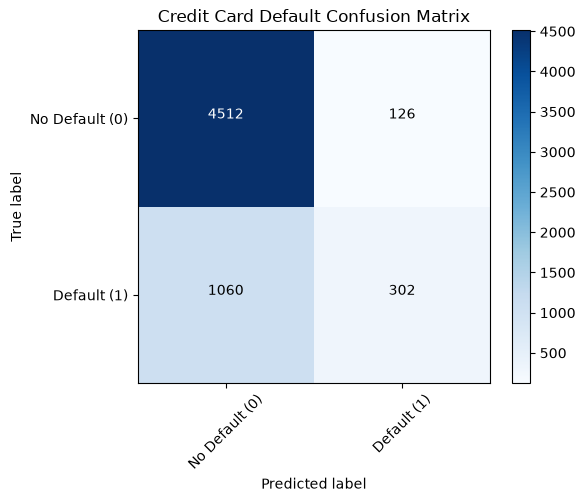


Classification Report:
              precision    recall  f1-score   support

  No Default       0.81      0.97      0.88      4638
     Default       0.71      0.22      0.34      1362

    accuracy                           0.80      6000
   macro avg       0.76      0.60      0.61      6000
weighted avg       0.79      0.80      0.76      6000



In [62]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import itertools

# Calculate Confusion Matrix
cm = confusion_matrix(y_test, yhat, labels=[0, 1])

# Print Confusion Matrix
print("Confusion Matrix:")
print(cm)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Credit Card Default Confusion Matrix')
plt.colorbar()

classes = ['No Default (0)', 'Default (1)']
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

thresh = cm.max() / 2.

for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(
        j, i, format(cm[i, j], 'd'),
        horizontalalignment="center",
        color="white" if cm[i, j] > thresh else "black"
    )

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    yhat,
    target_names=['No Default', 'Default']
))